# Semiconductor Devices and Amplifiers

This notebook exercises CirKreety's nonlinear device path using a diode limiter, a BJT common-emitter amplifier, and an NMOS common-source amplifier. Each netlist includes its own compact model cards. These are educational model subsets, not manufacturer-qualified device models.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from examples.notebook_support import run_example, ac_response, transient_trace, component_metric, measure_signal

## 1. Diode limiter

A sinusoidal source drives a resistor and diode clamp. Inspect the diode operating metric and compare the source and clamped output.

In [2]:
diode = run_example("diode_clamp")
print(diode.summary())
td, vin_d = transient_trace(diode, node_name="in")
_, vout_d = transient_trace(diode, node_name="out")
diode_device = component_metric(diode, "D1")
print("Diode terminal voltage:", diode_device.get("voltage_V"), "V")
print("Diode current:", diode_device.get("current_A"), "A")
print("Operating state:", diode_device.get("operating_state"))

{'title': 'Diode limiter and clamp waveform', 'status': 'success', 'validation_status': 'success', 'kcl_check': 'passed', 'backend': 'nonlinear_analog', 'analysis_status': {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'success', 'frequency_analysis': 'not_applicable', 'transfer_function': 'not_applicable', 'state_space': 'not_applicable'}, 'component_count': 3, 'node_count': 2, 'warnings': 0, 'errors': 0}
Diode terminal voltage: 0.0 V
Diode current: 0.0 A
Operating state: reverse_or_cutoff


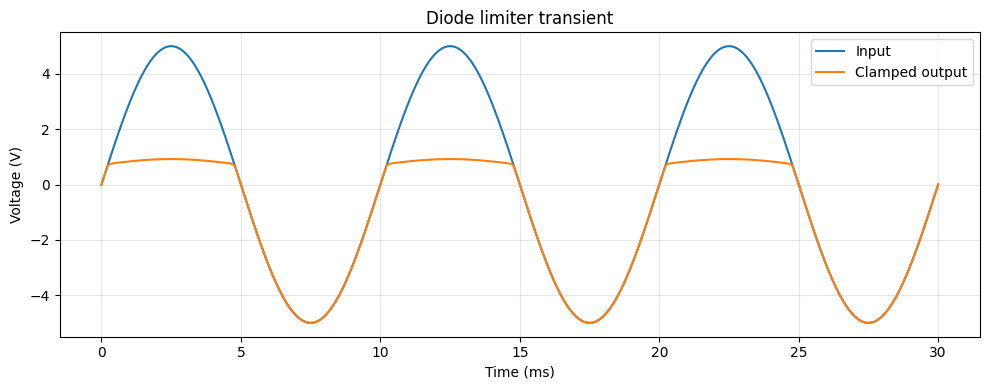

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(td * 1e3, vin_d, label="Input")
ax.plot(td * 1e3, vout_d, label="Clamped output")
ax.set(title="Diode limiter transient", xlabel="Time (ms)", ylabel="Voltage (V)")
ax.grid(True, alpha=0.3); ax.legend(); fig.tight_layout(); plt.show()

## 2. BJT common-emitter amplifier

The divider biases the NPN transistor. The transient source is a small pulse around zero and the AC source is used for small-signal response. The collector is explicitly selected as the output.

In [4]:
bjt = run_example("bjt_common_emitter")
print(bjt.summary())
q1 = component_metric(bjt, "Q1")
print(f"VBE              : {q1['VBE_V']:.4f} V")
print(f"VCE              : {q1['VCE_V']:.4f} V")
print(f"Collector current: {q1['collector_current_A'] * 1e3:.4f} mA")
print(f"Base current     : {q1['base_current_A'] * 1e6:.4f} µA")
print("Operating region :", q1["operating_region"])
fb, gb, pb = ac_response(bjt)
tb, vc = transient_trace(bjt, node_name="c")

{'title': 'NPN common-emitter amplifier', 'status': 'success', 'validation_status': 'success', 'kcl_check': 'passed', 'backend': 'nonlinear_analog', 'analysis_status': {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'success', 'frequency_analysis': 'not_applicable', 'transfer_function': 'not_applicable', 'state_space': 'not_applicable'}, 'component_count': 9, 'node_count': 5, 'warnings': 0, 'errors': 0}
VBE              : 0.7904 V
VCE              : 4.4789 V
Collector current: 0.4733 mA
Base current     : 4.7327 µA
Operating region : forward_active


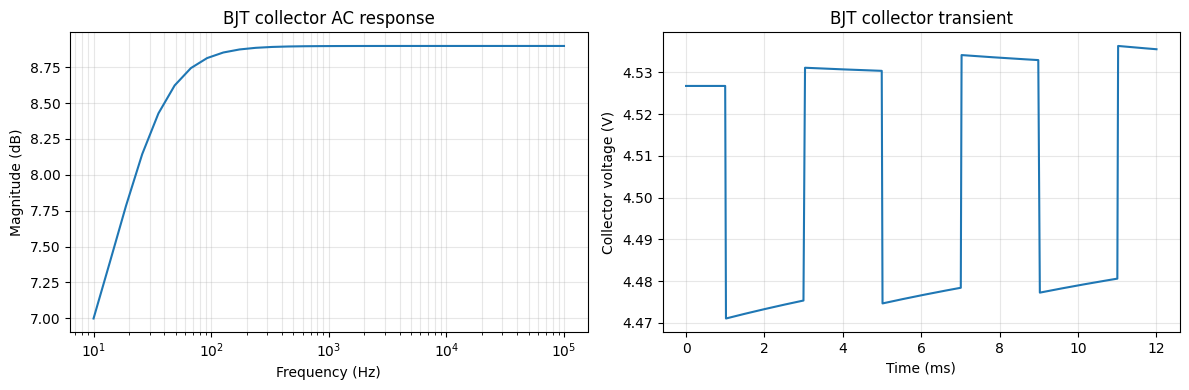

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogx(fb, gb)
axes[0].set(title="BJT collector AC response", xlabel="Frequency (Hz)", ylabel="Magnitude (dB)")
axes[0].grid(True, which="both", alpha=0.3)
axes[1].plot(tb * 1e3, vc)
axes[1].set(title="BJT collector transient", xlabel="Time (ms)", ylabel="Collector voltage (V)")
axes[1].grid(True, alpha=0.3)
fig.tight_layout(); plt.show()

## 3. NMOS common-source amplifier

The circuit uses a gate divider, source degeneration resistor with a bypass capacitor, drain resistor, and AC-coupled input. The Level-1 MOSFET model is used only within its implemented parameter subset.

In [6]:
mos = run_example("mosfet_common_source")
print(mos.summary())
m1 = component_metric(mos, "M1")
print(f"VGS                  : {m1['VGS_V']:.4f} V")
print(f"VDS                  : {m1['VDS_V']:.4f} V")
print(f"Drain current        : {m1['current_A'] * 1e3:.4f} mA")
print("Operating region     :", m1["operating_region"])
fm, gm, pm = ac_response(mos)
tm, vg = transient_trace(mos, node_name="gate")
_, vd = transient_trace(mos, node_name="drain")

{'title': 'NMOS common-source amplifier with capacitive input coupling', 'status': 'success', 'validation_status': 'success', 'kcl_check': 'passed', 'backend': 'nonlinear_analog', 'analysis_status': {'dc_operating_point': 'success', 'dc_sweep': 'success', 'ac_sweep': 'success', 'transient': 'success', 'frequency_analysis': 'not_applicable', 'transfer_function': 'not_applicable', 'state_space': 'not_applicable'}, 'component_count': 9, 'node_count': 5, 'warnings': 0, 'errors': 0}
VGS                  : 1.8185 V
VDS                  : 0.9903 V
Drain current        : 1.9315 mA
Operating region     : saturation


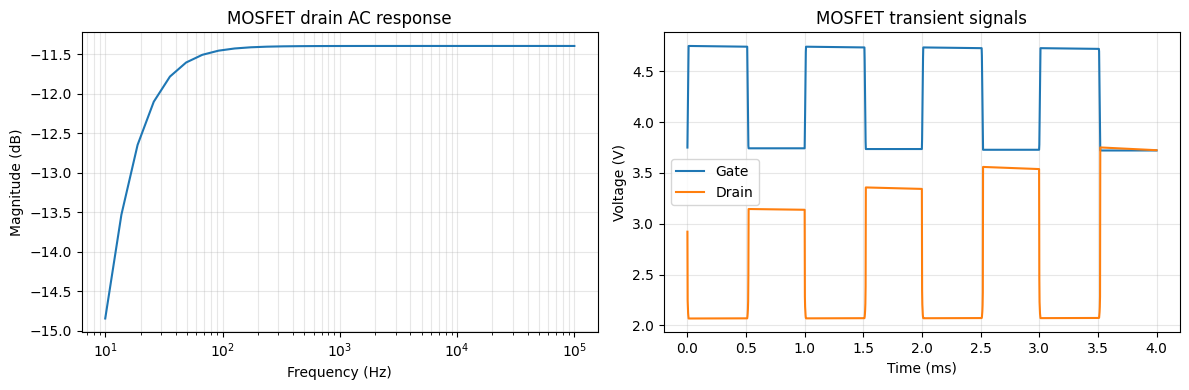

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogx(fm, gm)
axes[0].set(title="MOSFET drain AC response", xlabel="Frequency (Hz)", ylabel="Magnitude (dB)")
axes[0].grid(True, which="both", alpha=0.3)
axes[1].plot(tm * 1e3, vg, label="Gate")
axes[1].plot(tm * 1e3, vd, label="Drain")
axes[1].set(title="MOSFET transient signals", xlabel="Time (ms)", ylabel="Voltage (V)")
axes[1].grid(True, alpha=0.3); axes[1].legend()
fig.tight_layout(); plt.show()

## Interpretation and model boundaries

A nonlinear DC operating point describes static bias; the transient run describes the time-domain response; an AC sweep is a local small-signal linearization around the operating point. These are different analyses and should not be mixed. Check each component model's supported parameters in the report diagnostics. This notebook does not assess thermal stability, safe operating area, device process corners, PCB parasitics, or manufacturer-specific behavior.

In [8]:
for label, result in (("Diode", diode), ("BJT", bjt), ("MOSFET", mos)):
    print(f"{label:8s} status={result.status:9s} backend={result.summary()['backend']}")
    print("         artifacts:", result.artifacts["analysis_json"])

Diode    status=success   backend=nonlinear_analog
         artifacts: reports/notebook_examples/diode_clamp/analysis.json
BJT      status=success   backend=nonlinear_analog
         artifacts: reports/notebook_examples/bjt_common_emitter/analysis.json
MOSFET   status=success   backend=nonlinear_analog
         artifacts: reports/notebook_examples/mosfet_common_source/analysis.json
